<a href="https://colab.research.google.com/github/hilalkaynarcali/goruntu-isleme/blob/main/harmonik_vekt%C3%B6r.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
N = 256
fs = 256
t = np.arange(N) / fs

sinyal1 = 12 * np.sin(2 * np.pi * 50 * t)
sinyal2 = 5 * np.sin(2 * np.pi * 30 * t)

rng = np.random.default_rng(42)

gurultulu1 = sinyal1 + rng.uniform(-2.4, 2.4, N)
gurultulu2 = sinyal2 + rng.uniform(-1, 1, N)

toplam_sinyal = gurultulu1 + gurultulu2
temiz_toplam = sinyal1 + sinyal2

In [3]:
def dft_hesapla(vektor):

    N = len(vektor)

    if N == 0 or (N & (N - 1)) != 0:
        raise ValueError("Vektör boyutu 2'nin kuvveti olmalıdır.")

    harmonikler = np.zeros(N, dtype=complex)
    n = np.arange(N)

    for k in range(N):
        harmonikler[k] = np.sum(
            vektor * np.exp(-2j * np.pi * k * n / N)
        )

    return harmonikler

In [4]:
def ters_dft(harmonikler):

    N = len(harmonikler)
    k = np.arange(N)

    sinyal = np.zeros(N, dtype=complex)

    for n in range(N):
        sinyal[n] = np.sum(
            harmonikler * np.exp(2j * np.pi * k * n / N)
        ) / N

    return sinyal.real

In [5]:
def frekans_filtresi(vektor, esik_orani=0.1):

    harmonikler = dft_hesapla(vektor)

    esik = np.max(np.abs(harmonikler)) * esik_orani

    filtreli_harmonikler = harmonikler.copy()

    filtreli_harmonikler[
        np.abs(filtreli_harmonikler) < esik
    ] = 0

    filtreli_sinyal = ters_dft(filtreli_harmonikler)

    return filtreli_sinyal, harmonikler, filtreli_harmonikler

In [6]:
veriler = {
    "1. Sinyal (50 Hz)": (gurultulu1, sinyal1),
    "2. Sinyal (30 Hz)": (gurultulu2, sinyal2),
    "Toplam Sinyal": (toplam_sinyal, temiz_toplam)
}

sonuclar = {}

for ad, (gurultulu, temiz) in veriler.items():

    filtreli, harmonikler, filtreli_harmonikler = frekans_filtresi(
        gurultulu, 0.1
    )

    sonuclar[ad] = (
        gurultulu,
        temiz,
        filtreli,
        harmonikler,
        filtreli_harmonikler
    )

    print(ad)
    print("Korunan harmonik sayısı:",
          np.count_nonzero(filtreli_harmonikler))
    print()

1. Sinyal (50 Hz)
Korunan harmonik sayısı: 2

2. Sinyal (30 Hz)
Korunan harmonik sayısı: 2

Toplam Sinyal
Korunan harmonik sayısı: 4



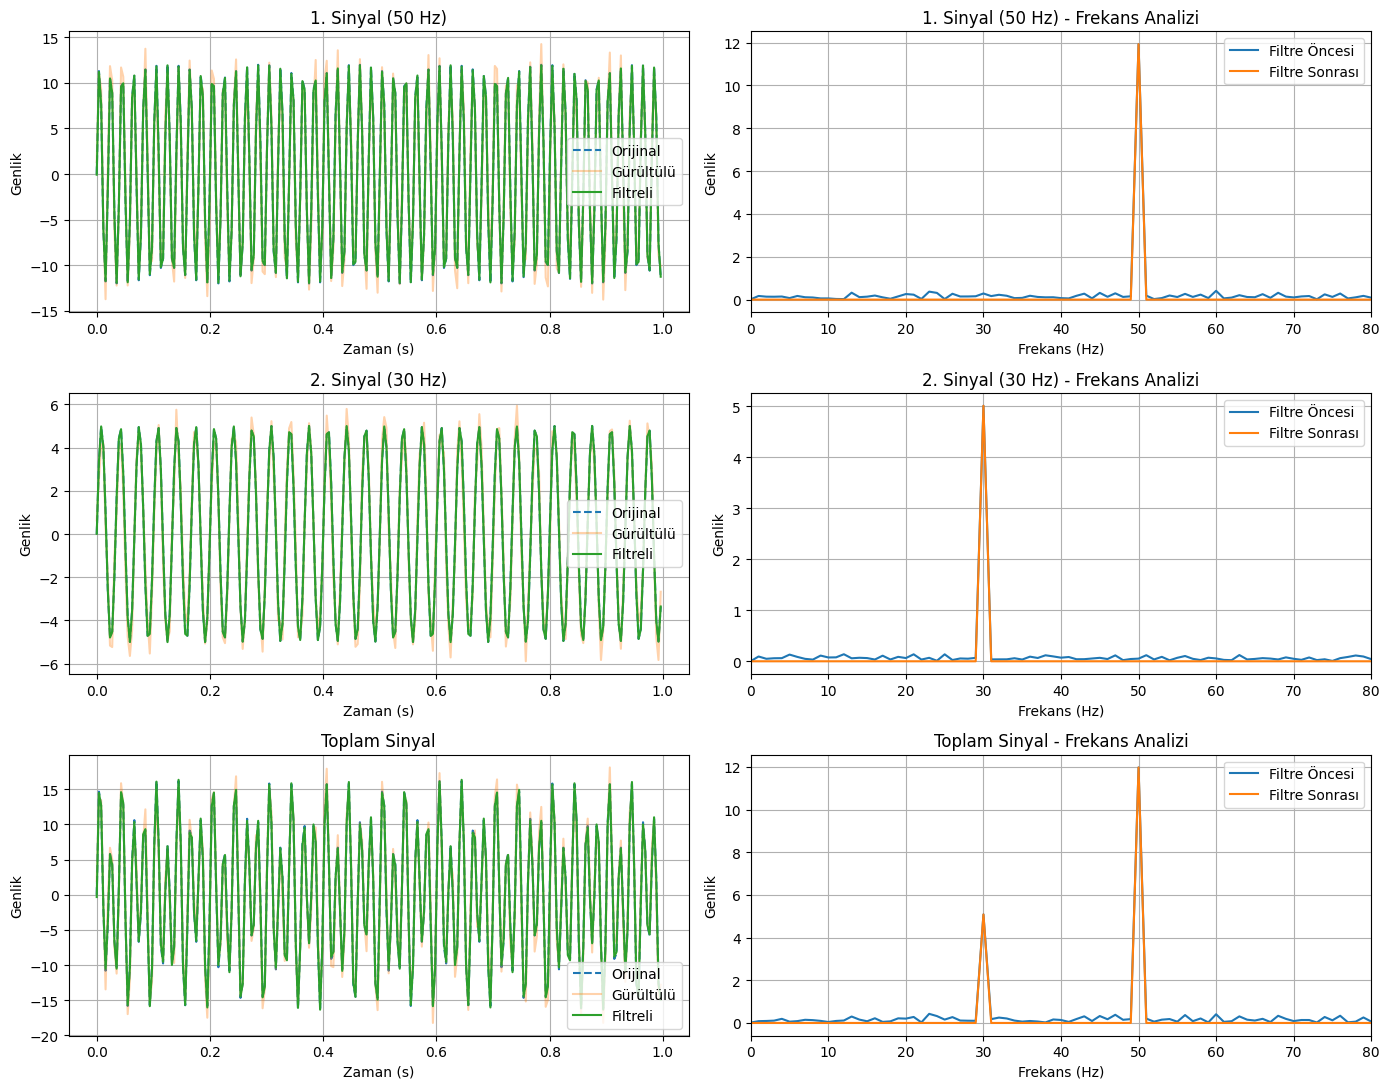

In [7]:
frekanslar = np.arange(N // 2 + 1) * fs / N

plt.figure(figsize=(14, 11))

for i, (ad, veriler) in enumerate(sonuclar.items()):

    gurultulu, temiz, filtreli, H, H_filt = veriler

    plt.subplot(3, 2, 2 * i + 1)

    plt.plot(t, temiz, label="Orijinal", linestyle="--")
    plt.plot(t, gurultulu, label="Gürültülü", alpha=0.35)
    plt.plot(t, filtreli, label="Filtreli")

    plt.title(ad)
    plt.xlabel("Zaman (s)")
    plt.ylabel("Genlik")
    plt.legend()
    plt.grid(True)

    plt.subplot(3, 2, 2 * i + 2)

    genlik_once = np.abs(H[:N // 2 + 1]) / N
    genlik_sonra = np.abs(H_filt[:N // 2 + 1]) / N

    genlik_once[1:-1] *= 2
    genlik_sonra[1:-1] *= 2

    plt.plot(frekanslar, genlik_once, label="Filtre Öncesi")
    plt.plot(frekanslar, genlik_sonra, label="Filtre Sonrası")

    plt.title(ad + " - Frekans Analizi")
    plt.xlabel("Frekans (Hz)")
    plt.ylabel("Genlik")
    plt.xlim(0, 80)
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.savefig("odev36_frekans_filtresi.png", dpi=200)
plt.show()

In [8]:
def rmse(a, b):
    return np.sqrt(np.mean((a - b) ** 2))

for ad, veriler in sonuclar.items():

    gurultulu, temiz, filtreli, H, H_filt = veriler

    hata_once = rmse(temiz, gurultulu)
    hata_sonra = rmse(temiz, filtreli)

    print(ad)
    print("Filtre öncesi RMSE:", round(hata_once, 4))
    print("Filtre sonrası RMSE:", round(hata_sonra, 4))
    print()

1. Sinyal (50 Hz)
Filtre öncesi RMSE: 1.3595
Filtre sonrası RMSE: 0.0702

2. Sinyal (30 Hz)
Filtre öncesi RMSE: 0.5807
Filtre sonrası RMSE: 0.0064

Toplam Sinyal
Filtre öncesi RMSE: 1.486
Filtre sonrası RMSE: 0.2029



In [9]:
H_filt = sonuclar["Toplam Sinyal"][4]

genlikler = np.abs(H_filt[:N // 2 + 1]) / N
genlikler[1:-1] *= 2

indeksler = np.argsort(genlikler[1:])[-2:] + 1

print("Filtre sonrası baskın frekanslar:")

for i in sorted(indeksler):
    print(
        f"{frekanslar[i]:.1f} Hz - Genlik: {genlikler[i]:.3f}"
    )

Filtre sonrası baskın frekanslar:
30.0 Hz - Genlik: 5.086
50.0 Hz - Genlik: 11.978


### Sonuç ve Yorum

Bu çalışmada iki farklı frekanstaki gürültülü sinyale ve bu sinyallerin toplamına frekans filtresi uygulanmıştır. Belirlenen eşik değerinin altında kalan harmonikler sıfırlanmış ve ters DFT kullanılarak sinyaller yeniden oluşturulmuştur.

Filtreleme sonucunda bütün sinyallerin RMSE değerlerinde belirgin düşüş görülmüştür. Toplam sinyalin frekans analizinde 30 Hz ve 50 Hz bileşenlerinin korunduğu, genliklerinin ise beklenen değerlere oldukça yakın olduğu gözlemlenmiştir. Bu sonuçlar frekans filtresinin gürültüyü azaltmada başarılı olduğunu göstermektedir.